# PCVK 2026 - Week 7: Segmentasi Citra dengan Thresholding

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Adidtiasmara/PCVK26_16_Firman/blob/main/Week7_16.ipynb)

**Muhammad Firman Aditiasmara** - PCVK26_16

---


In [29]:
DIR = '/home/adid/Kuliah/sem5/PCVK/gambar'


In [30]:
import cv2 as cv
import numpy as np
import google.colab.patches as cv2_imshow
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, morphology, segmentation, color, feature
from skimage.filters import gaussian
from skimage.segmentation import flood

## 3. Global Threshold Secara Manual (Threshold = 200)

Membuat **BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV** secara manual dengan NumPy (tanpa `cv.threshold()`).

| Jenis Global Threshold | Jika nilai piksel > thresh | Jika nilai piksel <= thresh |
|---|---|---|
| BINARY | Menjadi nilai maksimal | Menjadi 0 |
| BINARY_INV | Menjadi 0 | Menjadi nilai maksimal |
| TRUNC | Menjadi thresh | Nilai asli tetap |
| TOZERO | Nilai asli tetap | Menjadi 0 |
| TOZERO_INV | Menjadi 0 | Nilai asli tetap |

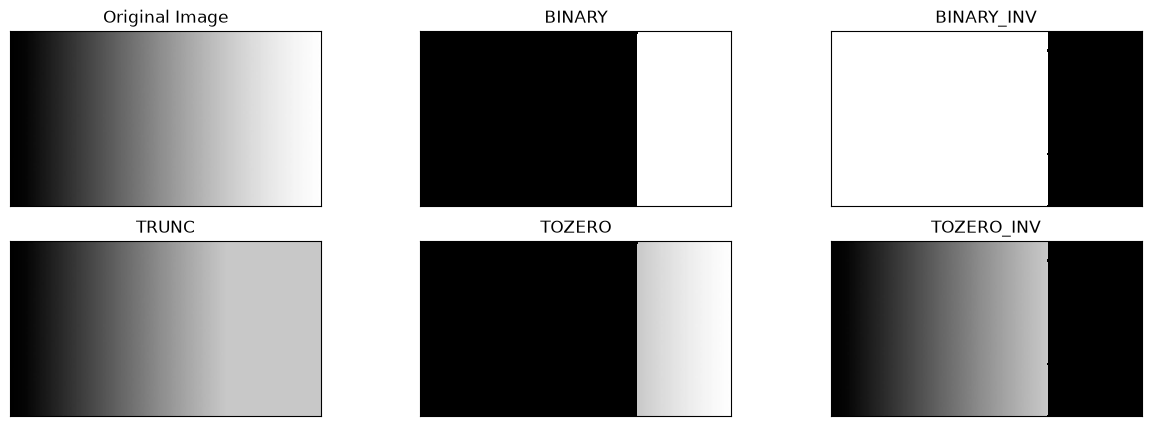

In [31]:
filename = (DIR + '/gradient.jpg')
img = cv.imread(filename)
thresh = 200 #nilai Threshold yang ditentukan
maxval=255

#1. threshold binary jika pixel di img>200, maka thresh1 bernilai 255(putih)
#selain itu bernilai 0(hitam)
ret,thresh1 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY)

#2. threshold binary inverse jika pixel>thresh, maka pixel bernilai 0; selain
#itu akan bernilai maxval
ret,thresh2 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY_INV)

#3. Threshold Truncate jika pixel>thresh, maka pixel bernilai thresh; selain
#itu akan bernilai tetap
ret,thresh3 = cv.threshold(img,thresh,maxval,cv.THRESH_TRUNC)

#4. Threshold Tozero jika pixel>thresh, maka pixel bernilai tetap; selain itu
#akan bernilai 0
ret,thresh4 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO)

#5. Threshold Tozero Inverse jika pixel>thresh, maka pixel bernilai 0; selain
#itu akan bernilai tetap
ret,thresh5 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO_INV)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC', 'TOZERO',
'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize = (15,5))
for i in range(len(images)):
  plt.subplot(2,3,i+1),plt.imshow(images[i],'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

## 4. Adaptive Threshold Secara Manual

Adaptive Mean dan Adaptive Gaussian **tanpa** `cv.threshold()`, `cv.adaptiveThreshold()`, maupun filter siap pakai, memakai citra Sudoku yang pencahayaannya tidak merata.

Ketentuan: global threshold manual ambang 127, jendela 11 x 11, C = 2, sigma = 2 untuk Gaussian.

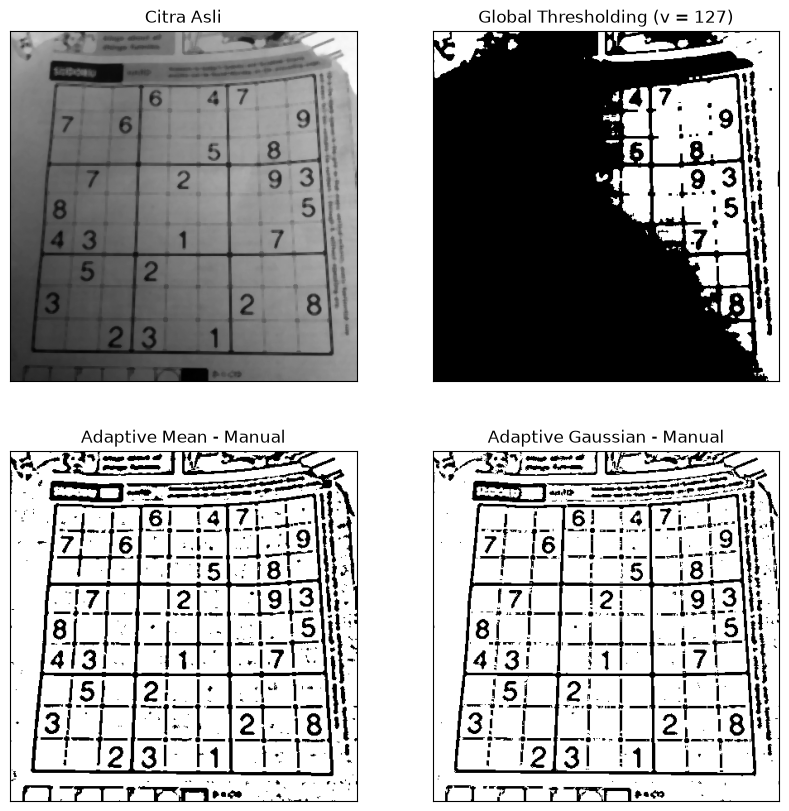

In [ ]:
filename = (DIR + '/sudoku-original.jpg')
img = cv.imread(filename)

# Median blur 5x5 manual (tanpa fungsi filter siap pakai)
def median_manual(img, k=5):
  pad = k // 2
  p = np.pad(img, ((pad, pad), (pad, pad), (0, 0)), mode='reflect')
  win = np.lib.stride_tricks.sliding_window_view(p, (k, k), axis=(0, 1))
  return np.median(win, axis=(-1, -2)).astype(np.uint8)

citra = median_manual(img, 5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127

# Global threshold manual
th1 = np.where(gray > thresh, 255, 0).astype(np.uint8)

# Adaptive threshold manual (mean & gaussian)
def _rata_1d(img, kernel, axis):
  r = len(kernel) // 2
  if axis == 1:
    p = np.pad(img, ((0, 0), (r, r)), mode='reflect')
    out = np.zeros_like(img, dtype=np.float64)
    for i, w in enumerate(kernel):
      out += w * p[:, i:i + img.shape[1]]
  else:
    p = np.pad(img, ((r, r), (0, 0)), mode='reflect')
    out = np.zeros_like(img, dtype=np.float64)
    for i, w in enumerate(kernel):
      out += w * p[i:i + img.shape[0], :]
  return out

def adaptive_manual(gray, block, C, sigma=None):
  if sigma is None:
    kernel = np.ones(block) / block
  else:
    ax = np.arange(block) - block // 2
    kernel = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    kernel /= kernel.sum()
  local = _rata_1d(_rata_1d(gray.astype(np.float64), kernel, 1), kernel, 0)
  T = local - C
  return np.where(gray > T, 255, 0).astype(np.uint8)

th2 = adaptive_manual(gray, 11, 2)
th3 = adaptive_manual(gray, 11, 2, sigma=2)

titles = ['Citra Asli', 'Global Thresholding (v = 127)',
'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize = (10,10))
for i in range(len(citra2)):
  plt.subplot(2,2,i+1),plt.imshow(citra2[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

## 5. Otsu Thresholding Tanpa Library

### A. Citra lena_gs_lc2.jpg
Otsu manual (tanpa `cv.threshold(..., cv.THRESH_OTSU)`), lalu dibandingkan dengan global threshold biasa.

/tmp/ipykernel_33658/1774976594.py:18: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_33658/1774976594.py:19: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


95


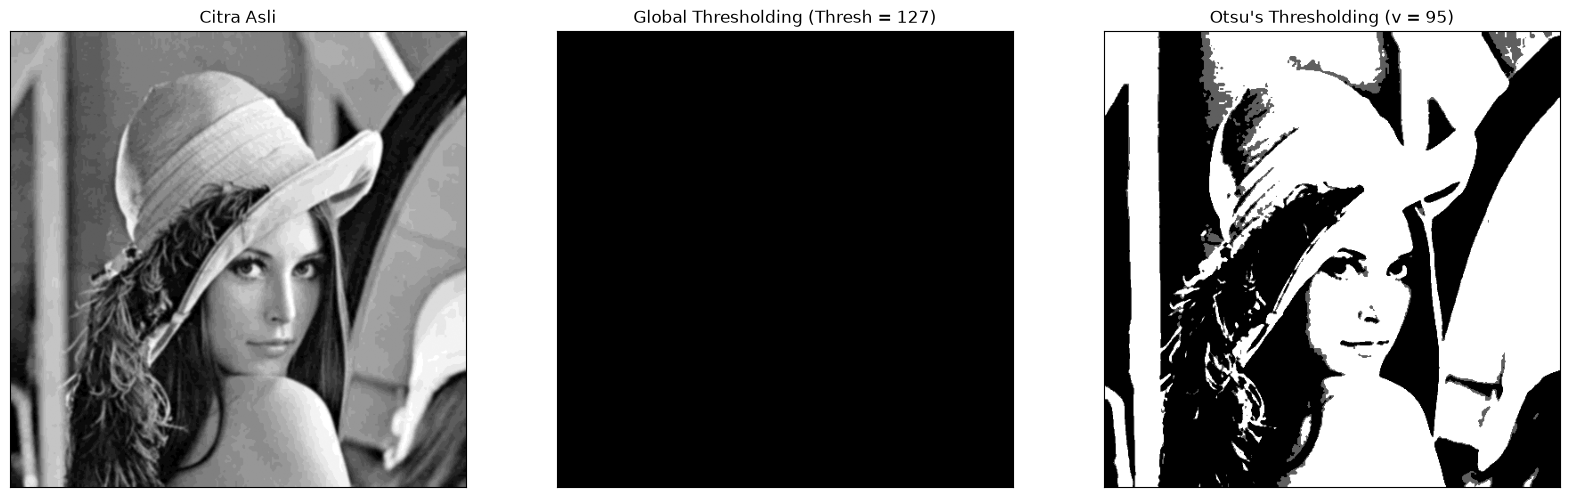

In [33]:
filename = (DIR + '/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

### Pertanyaan

**Mengapa hasil Binary Thresholding semua bernilai 0 atau hitam semua?**

Karena citra `lena_gs_lc2.jpg` adalah citra low contrast dengan rentang intensitas sempit (sekitar 85-108). Nilai threshold global 127 berada **di atas** seluruh rentang intensitas citra, sehingga tidak ada piksel yang nilainya > 127. Akibatnya semua piksel menjadi 0 (hitam).

Pada histogram, seluruh distribusi piksel berada di sebelah kiri garis ambang 127.

**Berapa angka ambang batas supaya gambar Lena masih terlihat?**

Ambang harus berada di dalam rentang intensitas citra, yaitu sekitar **85-108**. Otsu memilih nilai otomatis di sekitar **95**, sehingga gambar masih terlihat. Jadi nilai global threshold yang aman adalah di sekitar 95-100, bukan 127.

### B. Citra KTP Sendiri
Membandingkan hasil Otsu manual dengan global threshold biasa pada citra KTP.

/tmp/ipykernel_33658/1774976594.py:18: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


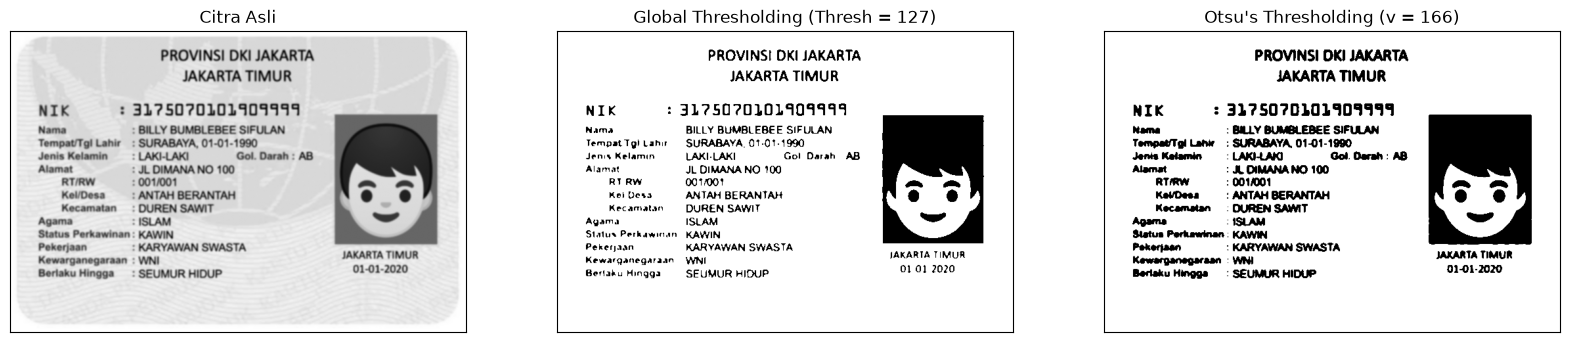

In [34]:
filename = (DIR + '/ktp_fulan.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

## 6. Segmentasi Berbasis Region

### A. Region Growing pada citra data.coins()
Menggunakan 3 seed: satu di dalam koin, satu di latar, dan satu tepat di tepi koin. Dijalankan dengan T = 5, 20, dan 60, lalu ditampilkan dalam grid (seed x T).

Seed (baris, kolom): (250, 300) | intensitas: 150.34615481468546
Seed (baris, kolom): (150, 200) | intensitas: 40.203718133645175
Seed (baris, kolom): (36, 43) | intensitas: 144.70655571875804


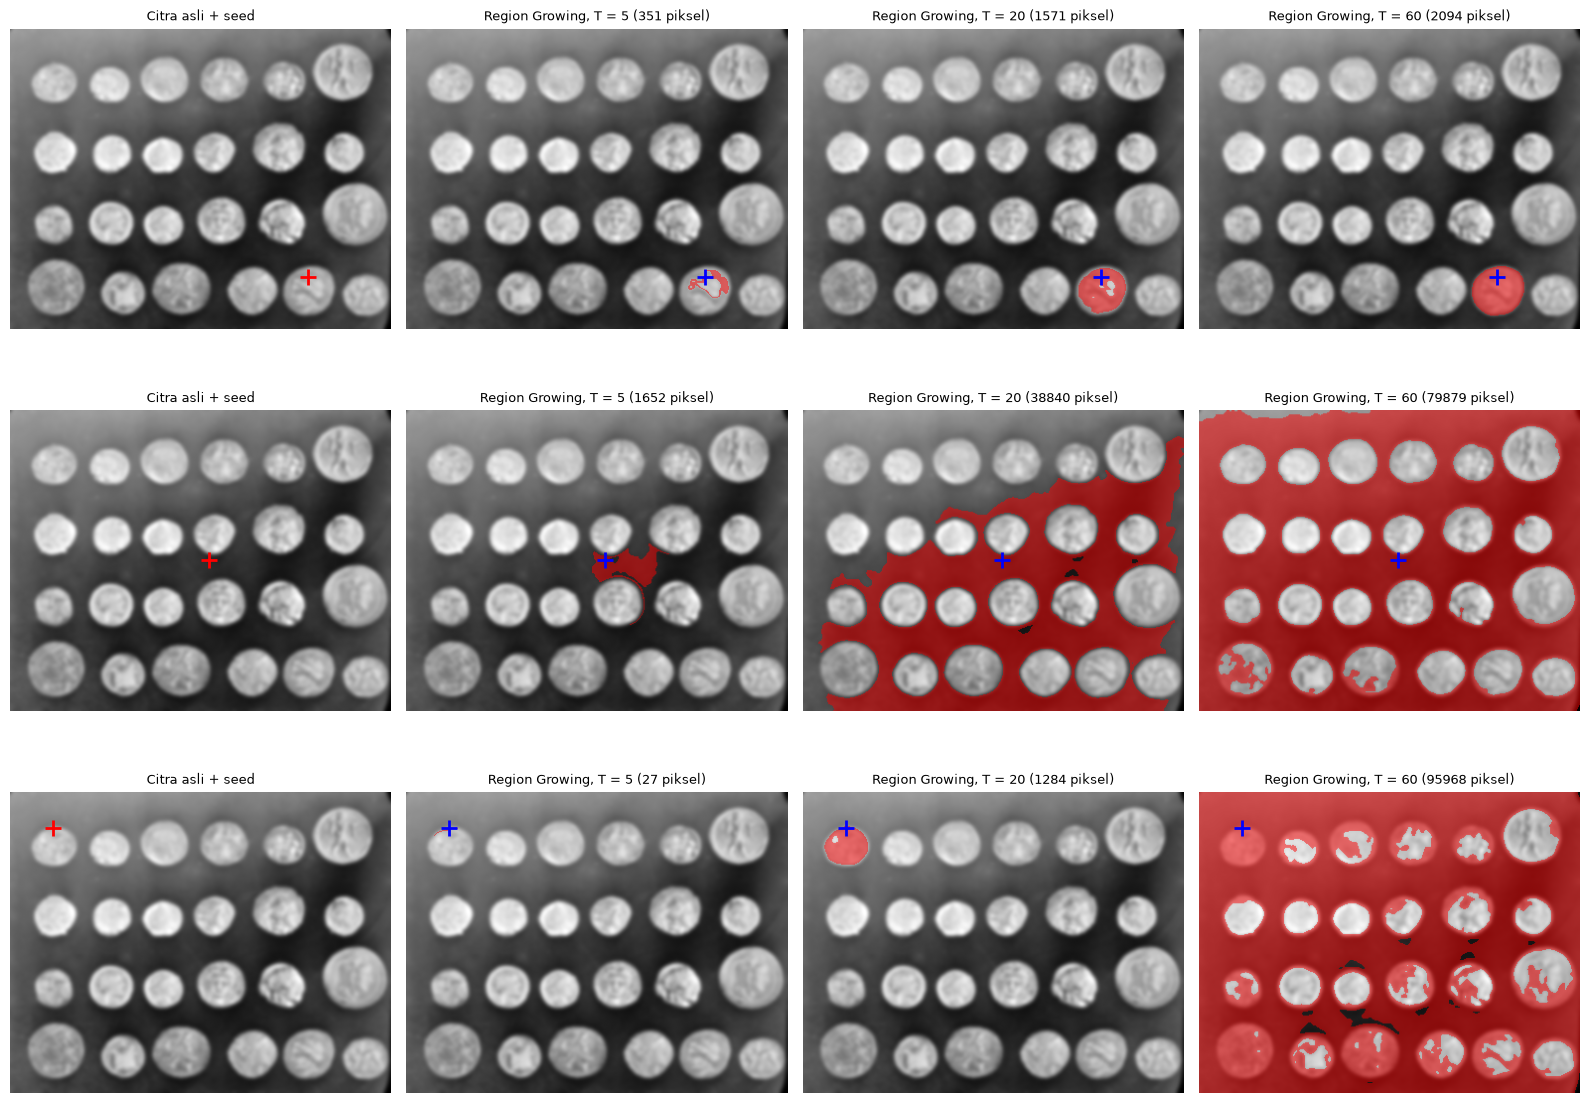

In [35]:
from skimage import data, filters

# citra coins (grayscale, 303 x 384), dihaluskan agar region lebih stabil
img_coins = filters.gaussian(data.coins().astype(float), sigma=2, preserve_range=True)

def region_growing(image, seed, T, conn=8):
    h, w = image.shape
    mask = np.zeros((h, w), bool)
    sr, sc = seed
    mask[sr, sc] = True
    total = image[sr, sc]
    count = 1
    q = deque([seed])
    if conn == 8:
        nb = [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]
    else:
        nb = [(-1,0),(1,0),(0,-1),(0,1)]
    while q:
        r, c = q.popleft()
        ref = total / count
        for dr, dc in nb:
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and not mask[nr, nc]:
                if abs(image[nr, nc] - ref) < T:
                    mask[nr, nc] = True
                    total += image[nr, nc]
                    count += 1
                    q.append((nr, nc))
    return mask

seeds = {'Koin': (250, 300), 'Latar': (150, 200), 'Tepi': (36, 43)}
Ts = [5, 20, 60]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i, (nama, seed) in enumerate(seeds.items()):
    print('Seed (baris, kolom):', seed, '| intensitas:', img_coins[seed])
    ax = axes[i, 0]
    ax.imshow(img_coins, cmap='gray')
    ax.plot(seed[1], seed[0], 'r+', markersize=12, markeredgewidth=2)
    ax.set_title('Citra asli + seed', fontsize=9)
    ax.axis('off')
    for j, T in enumerate(Ts):
        mask = region_growing(img_coins, seed, T)
        ax = axes[i, j + 1]
        ax.imshow(img_coins, cmap='gray')
        overlay = np.zeros((*img_coins.shape, 4))
        overlay[mask] = [1, 0, 0, 0.5]
        ax.imshow(overlay)
        ax.plot(seed[1], seed[0], 'b+', markersize=12, markeredgewidth=2)
        ax.set_title(f'Region Growing, T = {T} ({mask.sum()} piksel)', fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

### B. Segmentasi dengan skimage.segmentation.flood()
Fungsi ini menghasilkan mask region dari seed dengan menerima piksel yang terhubung dan intensitasnya berada dalam toleransi terhadap intensitas seed.

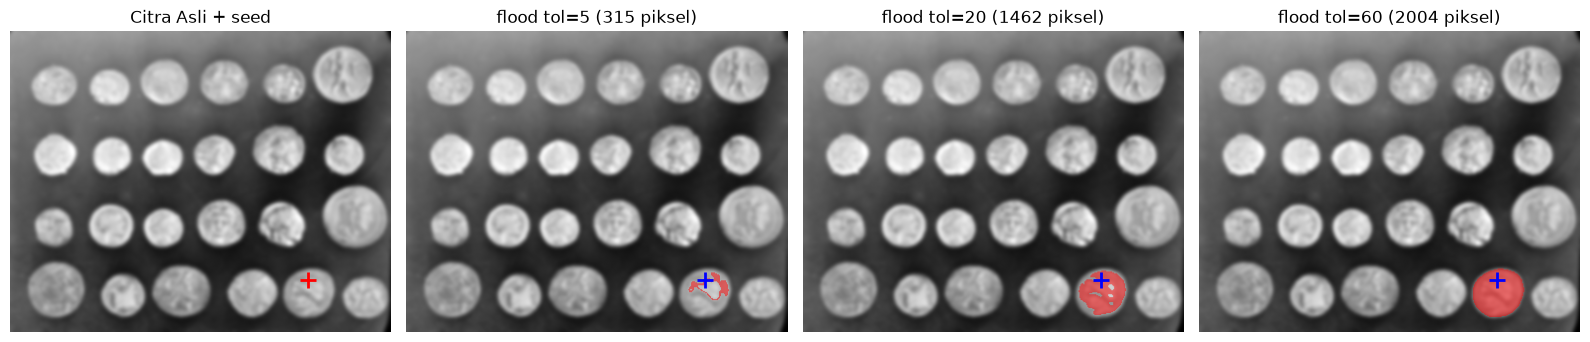

In [36]:
from skimage.segmentation import flood

seed = (250, 300)
tolerances = [5, 20, 60]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img_coins, cmap='gray')
axes[0].plot(seed[1], seed[0], 'r+', markersize=12, markeredgewidth=2)
axes[0].set_title('Citra Asli + seed')
axes[0].axis('off')

for ax, tol in zip(axes[1:], tolerances):
    mask = flood(img_coins, seed, tolerance=tol)
    overlay = np.zeros((*img_coins.shape, 4))
    overlay[mask] = [1, 0, 0, 0.5]
    ax.imshow(img_coins, cmap='gray')
    ax.imshow(overlay)
    ax.plot(seed[1], seed[0], 'b+', markersize=12, markeredgewidth=2)
    ax.set_title(f'flood tol={tol} ({mask.sum()} piksel)')
    ax.axis('off')
plt.tight_layout()
plt.show()

## D2. Tugas Kelompok — Perbandingan OCR Citra KTP

Tujuan: membandingkan kualitas pembacaan teks (OCR) **KTP setiap anggota kelompok** pada tiga citra masukan:

1. **Citra berwarna asli**
2. **Hasil segmentasi Otsu Thresholding**
3. **Hasil segmentasi Adaptive Thresholding**



In [ ]:
# Instal Tesseract + model bahasa Indonesia (cukup sekali).
# Di Google Colab jalankan sel ini; di komputer lokal pastikan paket
# tesseract-ocr dan tesseract-ocr-ind sudah terpasang pada sistem.
!sudo apt-get install -y tesseract-ocr tesseract-ocr-ind > /dev/null 2>&1
!pip install pytesseract -q

In [37]:
import difflib
import cv2 as cv
import numpy as np
import pandas as pd
import pytesseract
from pytesseract import Output
import matplotlib.pyplot as plt

# Pengaturan OCR — sama untuk semua metode dan semua anggota kelompok
LANG = 'ind'
PSM = 6
CONF_MIN = 60


In [38]:
def normalisasi(s):
    return ' '.join(s.lower().split())

def siapkan_citra(path):
    """Tiga citra berukuran sama: berwarna asli, Otsu, dan Adaptive.

    Sesuai modul, kedua metode thresholding memakai implementasi manual dari
    jobsheet sebelumnya (bukan fungsi library) dan citra diubah ke grayscale
    lebih dulu, sehingga semua citra masukan berukuran sama:
      - otsu()            -> Tugas 5A (Otsu tanpa library)
      - adaptive_manual() -> Tugas 4  (adaptive Gaussian tanpa cv.adaptiveThreshold)
    """
    img  = cv.imread(path)                       # citra berwarna asli
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)   # grayscale untuk thresholding
    otsu_img, _ = otsu(gray)                             # Otsu manual (Tugas 5A)
    adaptif = adaptive_manual(gray, 31, 25, sigma=10)    # adaptive Gaussian manual (Tugas 4)
    return img, otsu_img, adaptif

def baca_teks(img):
    """OCR dengan bahasa dan --psm yang sama agar perbandingan konsisten."""
    citra_ocr = cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img
    return pytesseract.image_to_string(citra_ocr, config=f'--oem 3 --psm {PSM} -l {LANG}')

def gambar_kotak(img, conf_min=CONF_MIN):
    """Citra RGB berkotak hijau pada teks ber-confidence > conf_min beserta daftar confidence."""
    citra_ocr = cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img
    data = pytesseract.image_to_data(citra_ocr, config=f'--oem 3 --psm {PSM} -l {LANG}',
                                     output_type=Output.DICT)
    vis = img.copy() if img.ndim == 3 else cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    confs = []
    for i, teks in enumerate(data['text']):
        if teks.strip() == '':
            continue
        conf = int(data['conf'][i])
        if conf >= 0:
            confs.append(conf)
        if conf > conf_min:
            x, y, w, h = data['left'][i], data['top'][i], data['width'][i], data['height'][i]
            cv.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return cv.cvtColor(vis, cv.COLOR_BGR2RGB), confs

def cocok(item, teks):
    """Cocok bila seluruh huruf/angka item ada pada hasil OCR (abaikan besar-kecil huruf dan spasi tepi)."""
    return normalisasi(item) in normalisasi(teks)

def baris_terdekat(item, teks, cutoff=0.55):
    """Baris OCR yang paling mendekati item acuan, untuk ditampilkan pada tabel."""
    target = normalisasi(item)
    baris = [l.strip() for l in teks.splitlines() if l.strip()]
    best, best_r = '-', 0.0
    for l in baris:
        if target in normalisasi(l):
            return l
        r = difflib.SequenceMatcher(None, target, normalisasi(l)).ratio()
        if r > best_r:
            best_r, best = r, l
    return best if best_r >= cutoff else '-'

def potong(teks, maks=24):
    """Pendekkan teks agar lebar kolom tabel tetap rapi."""
    teks = ' '.join(str(teks).split())
    return teks if len(teks) <= maks else teks[:maks - 1] + '~'

def tabel_border(df, judul=''):
    """Cetak DataFrame sebagai tabel teks berbatas (tanpa library tambahan)."""
    kolom = list(df.columns)
    isi = df.astype(str).values.tolist()
    lebar = [max([len(str(c))] + [len(str(r[j])) for r in isi])
             for j, c in enumerate(kolom)]
    def garis(kiri, tengah, kanan):
        return kiri + tengah.join('-' * (w + 2) for w in lebar) + kanan
    def baris(nilai):
        return '| ' + ' | '.join(str(v).ljust(w) for v, w in zip(nilai, lebar)) + ' |'
    if judul:
        print(judul)
    print(garis('+', '+', '+'))
    print(baris(kolom))
    print(garis('+', '+', '+'))
    for r in isi:
        print(baris(r))
    print(garis('+', '+', '+'))


In [ ]:
# Label field yang SAMA untuk semua anggota
ACUAN = ['NAMA', 'TEMPAT/TGL', 'ALAMAT', 'RT/RW', 'KEL/DESA', 'KECAMATAN',
         'AGAMA', 'STATUS PERKAWINAN', 'PEKERJAAN', 'KEWARGANEGARAAN',
         'BERLAKU HINGGA']

# Daftar KTP tiap 
DAFTAR_KTP = [
    ('Firman',   DIR + '/KTP_Adid.jpeg'),
    ('Ghofur', DIR + '/KTP_ghofur.jpeg'),
    ('Ihsan',  DIR + '/KTP_ihsan.jpeg'),
    ('Salma',  DIR + '/KTP_salma.jpeg'),
]

ringkasan = []
for nama, path in DAFTAR_KTP:
    img, citra_otsu, citra_adaptif = siapkan_citra(path)
    metode = [('Berwarna asli', img), ('Segmentasi Otsu', citra_otsu),
              ('Segmentasi Adaptive', citra_adaptif)]

    # Langkah 2 & 3: OCR + tampilkan area teks berkotak hijau (confidence > CONF_MIN)
    hasil, conf_avg = {}, {}
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (label, im) in zip(axes, metode):
        hasil[label] = baca_teks(im)
        vis, confs = gambar_kotak(im)
        conf_avg[label] = float(np.mean(confs)) if confs else 0.0
        ax.imshow(vis)
        ax.set_title(label)
        ax.axis('off')
    plt.suptitle(f'KTP {nama} - area teks terdeteksi (confidence > {CONF_MIN})')
    plt.tight_layout()
    plt.show()

    # Langkah 4: tabel perbandingan item acuan
    rows, tepat = [], {m[0]: 0 for m in metode}
    for i, item in enumerate(ACUAN, 1):
        row = {'No.': i, 'Teks sebenarnya': item}
        for label, _ in metode:
            m = cocok(item, hasil[label])
            tepat[label] += int(m)
            row[f'OCR {label}'] = f'{"V" if m else "-"} ' + potong(baris_terdekat(item, hasil[label]))
        rows.append(row)
    print()
    tabel_border(pd.DataFrame(rows), f'Tabel perbandingan OCR - KTP {nama}')

    # Bukti teks mentah hasil OCR tiap metode
    for label, _ in metode:
        print(f'\n----- Teks mentah OCR - KTP {nama} ({label}) -----')
        print(hasil[label].strip())

    for label, _ in metode:
        ringkasan.append({
            'Anggota': nama,
            'Citra masukan OCR': label,
            'Item terbaca tepat': f'{tepat[label]}/{len(ACUAN)}',
            'Kecocokan (%)': round(100 * tepat[label] / len(ACUAN), 1),
            'Rata-rata confidence': round(conf_avg[label], 1),
        })

In [40]:
# Ringkasan keseluruhan: baris = anggota, kolom = metode OCR.
df = pd.DataFrame(ringkasan)
METODE = ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']

def pivot_ringkasan(fmt):
    baris = []
    for nama in df['Anggota'].unique():
        row = {'Anggota': nama}
        for m in METODE:
            r = df[(df['Anggota'] == nama) & (df['Citra masukan OCR'] == m)].iloc[0]
            row[m] = fmt(r)
        baris.append(row)
    return pd.DataFrame(baris)

tabel_border(pivot_ringkasan(lambda r: f"{r['Item terbaca tepat']} ({r['Kecocokan (%)']}%)"),
             'Kecocokan tiap metode - item tepat / persen')
tabel_border(pivot_ringkasan(lambda r: f"{r['Rata-rata confidence']}"),
             'Rata-rata confidence tiap metode')

Kecocokan tiap metode - item tepat / persen
+---------+---------------+-----------------+---------------------+
| Anggota | Berwarna asli | Segmentasi Otsu | Segmentasi Adaptive |
+---------+---------------+-----------------+---------------------+
| Firman  | 0/11 (0.0%)   | 6/11 (54.5%)    | 5/11 (45.5%)        |
| Ghofur  | 5/11 (45.5%)  | 3/11 (27.3%)    | 4/11 (36.4%)        |
| Ihsan   | 5/11 (45.5%)  | 2/11 (18.2%)    | 5/11 (45.5%)        |
| Salma   | 1/11 (9.1%)   | 1/11 (9.1%)     | 2/11 (18.2%)        |
+---------+---------------+-----------------+---------------------+
Rata-rata confidence tiap metode
+---------+---------------+-----------------+---------------------+
| Anggota | Berwarna asli | Segmentasi Otsu | Segmentasi Adaptive |
+---------+---------------+-----------------+---------------------+
| Firman  | 55.1          | 70.0            | 37.1                |
| Ghofur  | 51.2          | 29.2            | 26.9                |
| Ihsan   | 53.9          | 47.3       

### Pertanyaan Analisis

Berdasarkan tabel ringkasan di atas (4 anggota x 3 metode, 11 item acuan):

**1. Citra masukan mana yang menghasilkan pembacaan paling tepat?**

Secara **rata-rata kelompok**, citra **hasil Segmentasi Adaptive** paling tepat:

| Metode | Total item tepat | Rata-rata kecocokan |
|---|---|---|
| Berwarna asli | 11 / 44 | 25,0% |
| Segmentasi Otsu | 12 / 44 | 27,3% |
| Segmentasi Adaptive | 16 / 44 | **36,4%** |

Namun pembacaan **individu terbaik** justru **Segmentasi Otsu pada KTP Firman (6/11 = 54,5%)**. Jadi tidak ada satu metode yang menang di semua KTP — Adaptive unggul secara rata-rata, tetapi tiap anggota punya metode terbaiknya sendiri.

**2. Contoh kesalahan pembacaan (minimal dua).**

- **Label ber-slash hilang**: `RT/RW`, `TEMPAT/TGL`, dan `KEL/DESA` tidak pernah terbaca oleh metode apa pun. OCR menghapus garis miring, mis. pada KTP Firman `RT/RW` terbaca `RTARW`, `Kel/Desa` terbaca `Kei/Desa`.
- **Huruf tertukar / kata kacau pada citra berwarna**: pada KTP Firman (berwarna asli) `NAMA` terbaca acak (`h AKELAP`) dan `AGAMA` menjadi `J SLEAM`; pada KTP Salma `TEMPAT/TGL` terbaca `TempayTyiLahir` dan `BERLAKU HINGGA` terbaca `Baraku Mingga`.
- **Goresan putus pada Otsu**: `ALAMAT` pada KTP Firman terbaca `Aiamai` (huruf `l`/`m` pecah).

**3. Apakah segmentasi selalu meningkatkan ketepatan OCR?**

**Tidak.** Hasilnya bergantung citra:

- **Membantu**: KTP Firman — berwarna 0,0% menjadi Otsu 54,5%. Ini karena citra berwarna Firman (latar biru + foto disensor merah + miring) paling sulit dibaca Tesseract, dan thresholding berhasil membersihkan latar.
- **Merugikan**: KTP Ghofur — berwarna 45,5% turun ke Otsu 27,3%; KTP Ihsan — berwarna 45,5% turun ke Otsu 18,2%. Binarisasi menghapus gradasi abu-abu huruf dan membuat latar berpola guilloche ikut menjadi noise.

Kesimpulan: segmentasi membantu saat citra asli sulit (kontras/warna mengganggu), tetapi bisa merugikan saat citra asli sudah cukup jelas.

**4. Pengaruh warna atau pola latar belakang.**

Latar KTP biru dengan pola **guilloche** (garis halus melengkung) berpengaruh dua arah:
- Pada citra **berwarna**, Tesseract kesulitan membaca langsung citra 3-kanal (KTP Firman 0%), terutama bila ada foto/sensor berwarna dan kemiringan.
- Setelah **thresholding**, pola guilloche bisa ikut ter-biner menjadi bercak noise (terlihat pada KTP Ghofur), sehingga huruf terpecah.
- Teks hitam di atas latar biru muda sebenarnya kontrasnya cukup, sehingga pada KTP yang bersih (Ghofur/Ihsan) citra berwarna sudah terbaca baik tanpa segmentasi.

**5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?**

**Tidak.** 

| Metode | Rata-rata confidence | Rata-rata kecocokan |
|---|---|---|
| Berwarna asli | **52,6** (tertinggi) | 25,0% (terendah) |
| Segmentasi Otsu | 50,3 | 27,3% |
| Segmentasi Adaptive | 37,2 (terendah) | **36,4%** (tertinggi) |

Confidence hanya mengukur **keyakinan** Tesseract pada tiap kata, bukan kebenarannya. Pada citra berwarna, Tesseract yakin tinggi walau banyak kata yang salah; pada citra Adaptive, confidence lebih rendah tetapi lebih banyak item yang benar-benar cocok. Jadi confidence tinggi tidak menjamin akurasi tinggi — tetap harus dibandingkan dengan teks acuan.
